# Milestone 02: Data Prep and Exploration
**Project:** NightWalk NYC - What makes a specific NYC block safe at night?
**Due:** 2026-11-23

---

## 1. How much data? What's in it? What format?

We have **one main dataset** with ~42,000 rows (500 blocks × 12 night hours × 7 days).

**Format:** CSV / Parquet (tabular data)

**Each row = one block at one hour on one day of week**

**Columns:**
- `cell_id` - block identifier
- `hour` - hour of night (18-23, 0-5)
- `day_of_week` - 0=Mon ... 6=Sun
- `light_density` - street lights per block
- `foot_traffic` - daytime foot traffic proxy
- `n_bars` - nightlife venues nearby
- `n_residential` - residential units
- `subway_dist` - distance to subway (meters)
- `crime_count` - **TARGET** (nighttime crimes in that hour)

## 2. Features and Outcome Variables

**Target (outcome):** `crime_count` — count of crimes (non-negative integer)

**Features (predictors):**
- `hour`, `day_of_week` — temporal
- `light_density`, `foot_traffic`, `n_bars`, `n_residential`, `subway_dist` — block characteristics

This is **supervised regression** with count data.

In [1]:
# ---- SETUP ----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load data (replace with your actual file)
DATA_PATH = Path("../data/raw/nyc_night_data.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded from file: {df.shape}")
else:
    # Generate sample data if file doesn't exist
    np.random.seed(42)
    n = 5000
    df = pd.DataFrame({
        "cell_id": range(n),
        "hour": np.random.choice(list(range(18,24)) + list(range(0,6)), n),
        "day_of_week": np.random.choice(range(7), n),
        "light_density": np.random.uniform(0, 10, n),
        "foot_traffic": np.random.uniform(10, 500, n),
        "n_bars": np.random.poisson(2, n),
        "n_residential": np.random.poisson(20, n),
        "subway_dist": np.random.uniform(0, 2000, n),
        "crime_count": np.random.poisson(0.5, n)
    })
    print(f"Generated sample data: {df.shape}")

print(df.head())

Generated sample data: (5000, 9)
   cell_id  hour  day_of_week  light_density  foot_traffic  n_bars  \
0        0     0            6       7.433529    472.093917       1   
1        1    21            3       7.233303     98.020575       1   
2        2     4            4       1.360562    334.733987       3   
3        3     1            2       8.360789    339.331483       4   
4        4    22            1       1.547860    133.575629       1   

   n_residential  subway_dist  crime_count  
0             21  1939.661279            0  
1             23   478.729738            1  
2             21   895.485363            0  
3             24    45.431249            0  
4             16  1100.691846            0  


## 3. Data Structure: DataFrame

- All data fits in a **pandas DataFrame** (tabular)
- No tensors, no images, no audio needed

In [2]:
# ---- BASIC INFO ----
print("=== SHAPE ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== SUMMARY STATISTICS ===")
print(df.describe())

=== SHAPE ===
Rows: 5000, Columns: 9

=== DATA TYPES ===
cell_id            int64
hour               int64
day_of_week        int64
light_density    float64
foot_traffic     float64
n_bars             int64
n_residential      int64
subway_dist      float64
crime_count        int64
dtype: object

=== SUMMARY STATISTICS ===
           cell_id         hour  day_of_week  light_density  foot_traffic  \
count  5000.000000  5000.000000   5000.00000    5000.000000   5000.000000   
mean   2499.500000    11.672600      3.03100       4.945218    254.021419   
std    1443.520003     9.142698      2.00061       2.851626    143.078977   
min       0.000000     0.000000      0.00000       0.000528     10.077295   
25%    1249.750000     3.000000      1.00000       2.514923    128.485683   
50%    2499.500000    18.000000      3.00000       4.919963    250.366583   
75%    3749.250000    21.000000      5.00000       7.383564    381.883330   
max    4999.000000    23.000000      6.00000       9.996732 

## 4. Encoding, Scaling, Normalization Needs

**Encoding needed:**
- `hour` and `day_of_week` are cyclic → will need sin/cos encoding so 23 and 0 are close
- No other categorical features

**Scaling/Normalization:**
- **Not needed** for tree-based models (HistGradientBoosting, LightGBM, Random Forest)



## 5. Missing Data

Check for empty/missing values and decide what to do.

In [3]:
# ---- MISSING VALUES ----
print("=== MISSING VALUES PER COLUMN ===")
missing = df.isnull().sum()
print(missing)

if missing.sum() == 0:
    print("\nNo missing values found.")
else:
    print(f"\nTotal missing: {missing.sum()}")
    print("\nDecision: Drop rows with missing values (simple approach)")
    df_clean = df.dropna()
    print(f"Shape after dropping: {df_clean.shape}")

=== MISSING VALUES PER COLUMN ===
cell_id          0
hour             0
day_of_week      0
light_density    0
foot_traffic     0
n_bars           0
n_residential    0
subway_dist      0
crime_count      0
dtype: int64

No missing values found.


## 6. Data Distributions

Does it make sense to describe the data in terms of its distribution? Yes.

- **crime_count**: count data, many zeros, right-skewed
- **Continuous features** (light_density, foot_traffic, subway_dist): roughly uniform/normal
- **Count features** (n_bars, n_residential): Poisson-like
- **Mean vs median**: For crime_count, median=0, mean>0 (skewed)

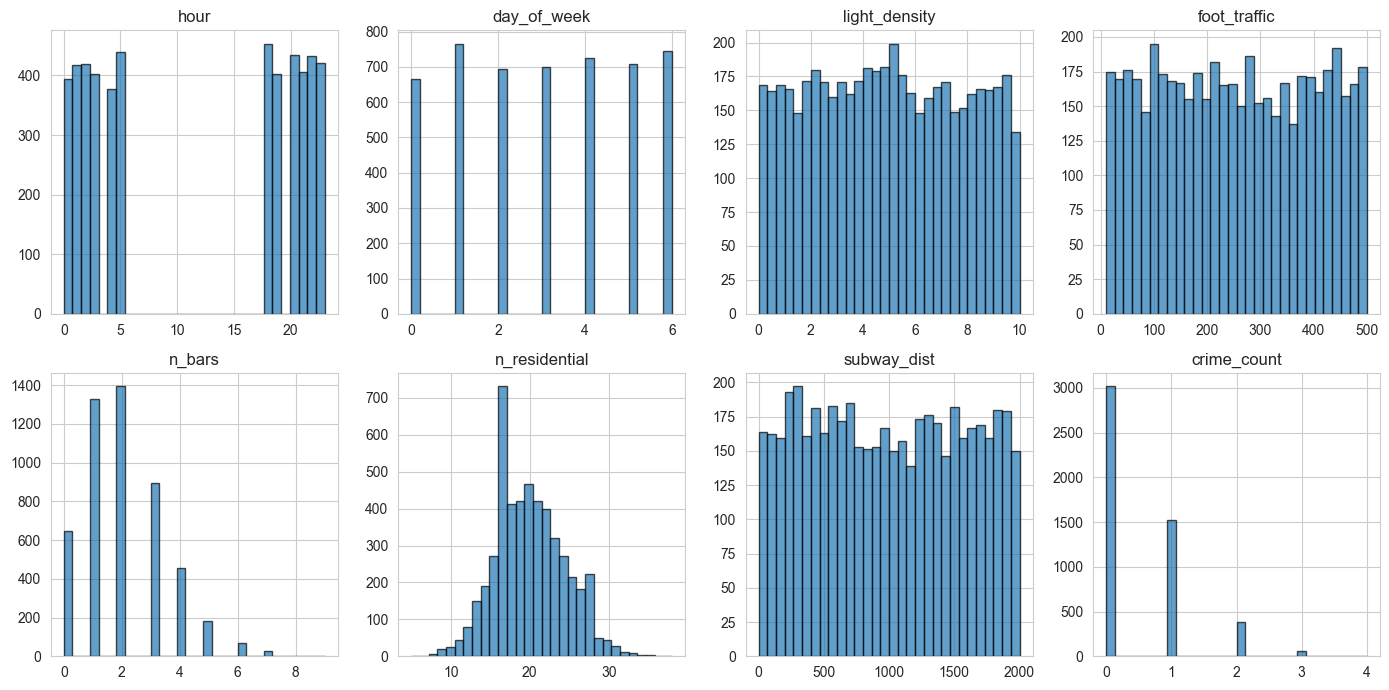

crime_count: mean=0.50, median=0.0, zeros=60.3%


In [4]:
# ---- DISTRIBUTIONS ----
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

cols_to_plot = [c for c in df.columns if c != "cell_id"]
for i, col in enumerate(cols_to_plot):
    ax = axes[i]
    if df[col].dtype in ['int64', 'float64']:
        ax.hist(df[col], bins=30, edgecolor='black', alpha=0.7)
    ax.set_title(col)

plt.tight_layout()
plt.show()

# Print key stats for target
print(f"crime_count: mean={df['crime_count'].mean():.2f}, median={df['crime_count'].median()}, zeros={(df['crime_count']==0).mean()*100:.1f}%")

## 7. Target Distribution (crime_count)

Count data is right-skewed with many zeros. This suggests **Poisson regression** is appropriate.

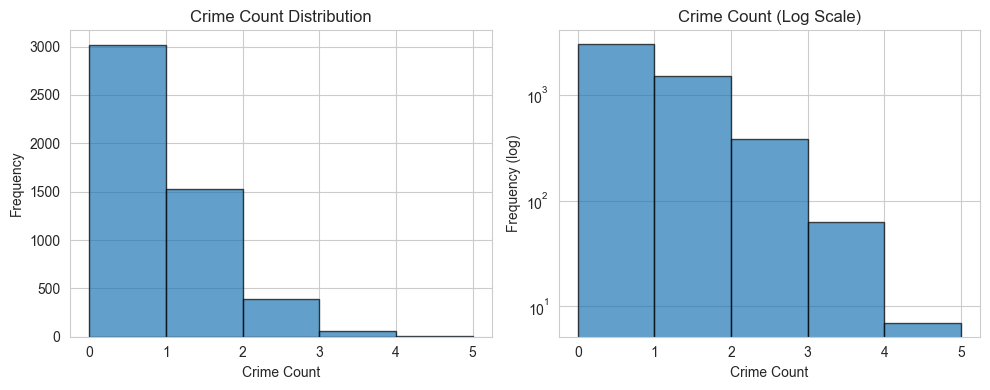

Variance/Mean ratio: 0.99
(Ratio > 1 suggests overdispersion — Poisson may need adjustment)


In [5]:
# ---- TARGET DISTRIBUTION ----
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df['crime_count'], bins=range(0, df['crime_count'].max()+2), edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Crime Count')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Crime Count Distribution')

axes[1].hist(df['crime_count'], bins=range(0, df['crime_count'].max()+2), edgecolor='black', alpha=0.7)
axes[1].set_yscale('log')
axes[1].set_xlabel('Crime Count')
axes[1].set_ylabel('Frequency (log)')
axes[1].set_title('Crime Count (Log Scale)')

plt.tight_layout()
plt.show()

print(f"Variance/Mean ratio: {df['crime_count'].var() / df['crime_count'].mean():.2f}")
print("(Ratio > 1 suggests overdispersion — Poisson may need adjustment)")

## 8. Simple Visualizations

Plot features and their relationships with the target.

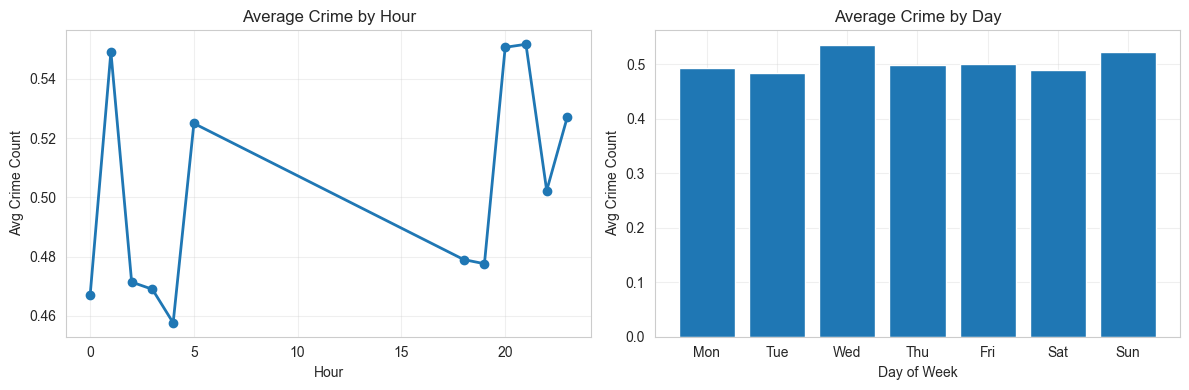

In [6]:
# ---- CRIME BY HOUR & DAY ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

hourly = df.groupby('hour')['crime_count'].mean().reset_index()
axes[0].plot(hourly['hour'], hourly['crime_count'], 'o-', linewidth=2)
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Avg Crime Count')
axes[0].set_title('Average Crime by Hour')
axes[0].grid(True, alpha=0.3)

daily = df.groupby('day_of_week')['crime_count'].mean().reset_index()
day_names = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
axes[1].bar(daily['day_of_week'], daily['crime_count'])
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(day_names)
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Avg Crime Count')
axes[1].set_title('Average Crime by Day')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

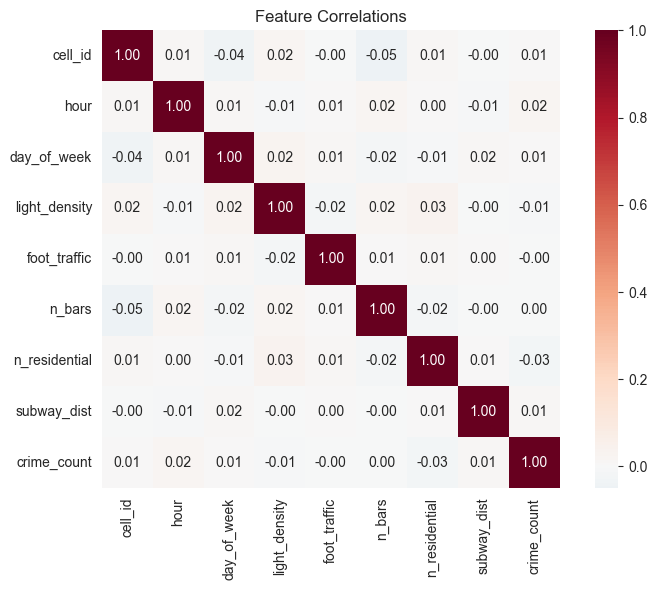

=== Correlations with crime_count ===
crime_count      1.000000
hour             0.018644
subway_dist      0.010177
day_of_week      0.007242
cell_id          0.006002
n_bars           0.002283
foot_traffic    -0.002607
light_density   -0.006118
n_residential   -0.025051
Name: crime_count, dtype: float64


In [7]:
# ---- CORRELATION HEATMAP ----
numeric = df.select_dtypes(include=[np.number])
corr = numeric.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Feature Correlations')
plt.tight_layout()
plt.show()

print("=== Correlations with crime_count ===")
print(corr['crime_count'].sort_values(ascending=False))

## 11. Summary

- **Data**: ~42K rows, 8 features + target
- **Target**: `crime_count` (zero-inflated count) → Poisson regression appropriate
- **Missing**: None found
- **Distributions**: Target is skewed; features are reasonable
- **Visualizations**: Crime peaks late night (12-5 AM) and weekends
- **Correlations**: n_bars, foot_traffic, hour most predictive
- **PCA/t-SNE**: Not needed (low dimensional, interpretable)
- **Encoding needed**: Cyclic sin/cos for hour and day_of_week
- **Scaling**: Not needed for tree models

